# Working with Images using TorchVision: a CIFAR-10 walkthrough

**CM4126 Computer Vision: lab notebook for the lecture "Working with Images using TorchVision"**

This notebook is a guided lab. Run it from top to bottom, one cell at a time, and read the text before each cell: it tells you what the cell does and why it matters. You do not need any previous PyTorch experience.

### Learning objectives

By the end of this notebook you will be able to:

1. Explain how an image is stored as a **tensor** and move between `[H, W, C]` and `[C, H, W]` layouts.
2. Build **transform pipelines** with `torchvision.transforms`: resize, crop, normalise and augment.
3. Load a dataset with `Dataset` and `DataLoader`, and make a **validation split** properly.
4. Use a **pretrained ResNet** to make predictions, and adapt it to a new task with **transfer learning**.
5. **Evaluate** a classifier with more than accuracy: confusion matrix, per-class metrics, class imbalance.
6. Apply **best practices**: sanity checks, learning-rate choice, schedulers, early stopping and checkpoints.

### How this notebook maps to the lecture

| Lecture section | Notebook section |
|---|---|
| 01 PyTorch basics: tensors | 1. PyTorch basics: tensors |
| 02 Images & transforms | 2. Images & transforms |
| 03 Datasets & DataLoaders | 3. Datasets & DataLoaders |
| 04 Pretrained models | 4. Pretrained models |
| 05 Transfer learning | 5. Transfer learning |
| 06 Evaluating properly | 6. Evaluating properly |
| 07 Best practices & hyperparameter tuning | 7. Best practices & hyperparameter tuning |
| 08 Beyond classification | 8. Beyond classification |

Each major section ends with **Key takeaways** and a short **Try it yourself** exercise. Solutions are hidden: click *Solution* to reveal them, but have a go first.

### The dataset: CIFAR-10

We use **CIFAR-10** throughout. It is a classic small benchmark:

- **60,000 colour images**, each only **32 × 32 pixels**.
- **10 classes**: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.
- **50,000 training** images and **10,000 test** images, with **6,000 images per class** in total.

The images are tiny, so they download quickly (about 170 MB, once) and train fast. They are also hard: at 32 × 32 a cat and a dog can look very similar, which makes the evaluation section interesting.

### Imports

First we import the libraries we need. **PyTorch** (`torch`) gives us tensors and neural network building blocks. **TorchVision** (`torchvision`) adds everything image-specific: datasets, transforms and pretrained models. **Matplotlib** draws plots and **NumPy** handles arrays. We print the versions so that, if something behaves differently on your machine, you can compare.

In [1]:
import copy, random, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.utils import make_grid, draw_bounding_boxes
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from tqdm import tqdm  # progress bars for the training loops

print("PyTorch:", torch.__version__, "| TorchVision:", torchvision.__version__)

PyTorch: 2.15.0 | TorchVision: 0.29.2


### Configuration

All the settings you might want to change live in **one cell**, so you never have to hunt through the notebook.

- `QUICK_RUN = True` uses small subsets of the data and few epochs, so the whole notebook runs on a laptop CPU in roughly 15 minutes or less. Set it to `False` for the full dataset and better accuracy (a GPU is strongly recommended for that).
- `IMG_SIZE` is the size we resize images to. Pretrained ImageNet models were trained at 224 × 224, but they also work at 128 × 128, which is much faster.
- `RUN_OPTUNA` and `RUN_DETECTOR` switch on two optional, slower cells near the end. They are off by default.

In [2]:
QUICK_RUN = True          # True: small subsets, few epochs (runs on a laptop CPU)
SEED = 42
BATCH_SIZE = 64
NUM_WORKERS = 0           # 0 is safest in notebooks on Windows/macOS; 2-4 on Linux
IMG_SIZE = 224 if not QUICK_RUN else 128   # pretrained models work at 128 too, and it's faster
TRAIN_SUBSET = 5000 if QUICK_RUN else None # None = full 45k training split
VAL_SUBSET = 1000 if QUICK_RUN else None   # None = full 5k validation split
TEST_SUBSET = 2000 if QUICK_RUN else None  # None = full 10k test set
EPOCHS_HEAD = 2 if QUICK_RUN else 5
EPOCHS_FINETUNE = 2 if QUICK_RUN else 5
DATA_DIR = "./data"       # CIFAR-10 is downloaded here (once)
RUN_OPTUNA = False        # optional hyperparameter search in section 7
RUN_DETECTOR = False      # optional object detector demo in section 8 (large download)

### Choosing a device

Neural networks run much faster on a **GPU**. PyTorch supports three kinds of hardware, and we pick the best one available:

- `cuda`: an NVIDIA GPU (most lab machines and Google Colab).
- `mps`: the GPU in Apple Silicon Macs (M1, M2, M3, ...).
- `cpu`: works everywhere, just slower.

Later we move both the model and each batch of data to this `device` with `.to(device)`. Both must be on the same device, or PyTorch raises an error.

In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")      # NVIDIA GPU
elif torch.backends.mps.is_available():
    device = torch.device("mps")       # Apple Silicon GPU
else:
    device = torch.device("cpu")       # works everywhere, just slower
print("Using device:", device)

Using device: mps


### Reproducibility: setting seeds

Training uses randomness everywhere: the random initial weights of a new layer, the order of shuffled batches, and random augmentations. A **seed** fixes the starting point of the random number generators, so running the notebook again gives (nearly) the same results. This matters when you compare two ideas: you want any difference to come from your change, not from luck.

We seed Python's `random`, NumPy and PyTorch. GPUs can still introduce tiny run-to-run differences, so expect your numbers to be close to, but not always identical to, the saved outputs.

In [4]:
def set_seed(seed):
    """Seed every random number generator we use."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)              # also seeds MPS on Apple Silicon
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Seed set to", SEED)

Seed set to 42


## 1. PyTorch basics: tensors

*Lecture section 01: PyTorch basics.*

A **tensor** is PyTorch's version of a NumPy array: a grid of numbers with any number of dimensions. Everything in PyTorch is a tensor: images, labels, model weights and predictions. Unlike NumPy arrays, tensors can live on a GPU and can track gradients for training.

### Creating a tensor

Two attributes tell you almost everything about a tensor: `.shape` (how many numbers along each dimension) and `.dtype` (what kind of number: `float32`, `uint8`, `int64`, ...). Maths on tensors is **element-wise**: `x * 2` doubles every entry.

In [5]:
x = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(x)
print("shape:", x.shape, "| dtype:", x.dtype)
print("x * 2 =\n", x * 2)           # element-wise maths
print("x + x =\n", x + x)
print("mean:", x.mean().item())     # .item() turns a one-number tensor into a Python float

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3]) | dtype: torch.float32
x * 2 =
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
x + x =
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
mean: 3.5


### An image is a grid of numbers

*Slide: "An image is a grid of numbers".*

Let's load CIFAR-10 **without any transform**. Each item is then a pair `(image, label)`, where the image is a **PIL image** (the standard Python image format) and the label is an integer from 0 to 9. `download=True` fetches the data into `./data` the first time; after that it is read from disk.

In [6]:
raw_train = datasets.CIFAR10(root=DATA_DIR, train=True, download=True)   # no transform: PIL images
raw_test = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)
classes = raw_train.classes                                              # list of the 10 class names
print(classes)
print("training images:", len(raw_train), "| test images:", len(raw_test))

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
training images: 50000 | test images: 10000


Now we pick one image and show it. `interpolation="nearest"` tells Matplotlib not to smooth the image, so you can see each of the 32 × 32 pixels as a separate square.

type: Image | size (W, H): (32, 32) | mode: RGB
label: 7 -> horse


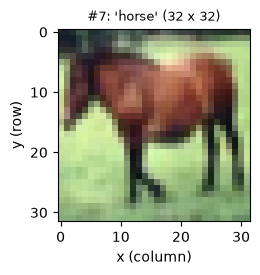

In [7]:
SAMPLE_IDX = 7                                   # try other numbers!
img, label = raw_train[SAMPLE_IDX]
print("type:", type(img).__name__, "| size (W, H):", img.size, "| mode:", img.mode)
print("label:", label, "->", classes[label])

plt.figure(figsize=(2.5, 2.5))
plt.imshow(img, interpolation="nearest")         # no smoothing: pixels stay visible
plt.title(f"#{SAMPLE_IDX}: '{classes[label]}' (32 x 32)", fontsize=9)
plt.xlabel("x (column)"); plt.ylabel("y (row)")
plt.show()

To the computer, this picture is just numbers. Converting the PIL image to a NumPy array shows its shape `[H, W, C]`: height, width and **3 colour channels** (red, green, blue). Each value is a `uint8` between 0 (dark) and 255 (bright).

The lecture showed this with a greyscale MNIST digit, which has a single channel. CIFAR has three, so below we print an 8 × 8 patch of **just the red channel**. The yellow box shows where the patch is.

array shape: (32, 32, 3) | dtype: uint8 | range: 9 to 248
Red channel, 8 x 8 patch:
 [[170 161 116 123 155 155 154 143]
 [141 140 103 104 140 147 144 127]
 [105 105  85 103 144 138 125 114]
 [ 71  69  84 132 144 126 108  92]
 [ 48  54 117 164 149 115  84  61]
 [ 47  57 111 116  94  70  49  35]
 [ 58  58  92 112  82  63  53  44]
 [ 43  44 121 199 174 152 139 135]]


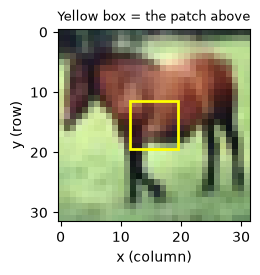

In [8]:
arr = np.array(img)                         # PIL -> NumPy array, layout [H, W, C]
print("array shape:", arr.shape, "| dtype:", arr.dtype, "| range:", arr.min(), "to", arr.max())
y0, x0 = 12, 12                             # top-left corner of the patch
print("Red channel, 8 x 8 patch:\n", arr[y0:y0 + 8, x0:x0 + 8, 0])

fig, ax = plt.subplots(figsize=(2.5, 2.5))
ax.imshow(arr, interpolation="nearest")
ax.add_patch(patches.Rectangle((x0 - 0.5, y0 - 0.5), 8, 8, edgecolor="yellow", fill=False, linewidth=2))
ax.set_title("Yellow box = the patch above", fontsize=9)
ax.set_xlabel("x (column)"); ax.set_ylabel("y (row)")
plt.show()

### A colour image: three channels

*Slide: "A colour image: three channels".*

A colour image is three greyscale grids stacked together. Below, each channel is shown in grey: **brighter means more of that colour** at that pixel. A white area is bright in all three channels; a strongly red area is bright only in the red channel.

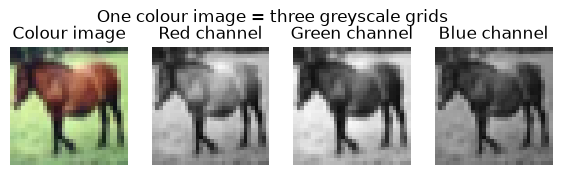

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(7, 2))
axes[0].imshow(arr, interpolation="nearest")
axes[0].set_title("Colour image")
for i, name in enumerate(["Red", "Green", "Blue"]):
    axes[i + 1].imshow(arr[:, :, i], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[i + 1].set_title(f"{name} channel")
for ax in axes:
    ax.axis("off")
fig.suptitle("One colour image = three greyscale grids")
plt.show()

### `[C, H, W]` vs `[H, W, C]`

*Slide: "Tensor shapes for images".*

Different libraries order the dimensions differently, and mixing them up is one of the most common bugs:

- **NumPy, PIL and Matplotlib** use `[H, W, C]` (channels last).
- **PyTorch** uses `[C, H, W]` (channels first), and models expect a **batch** dimension in front: `[N, C, H, W]`.

`permute` reorders dimensions, `unsqueeze(0)` adds a batch dimension of size 1, and `.to(device)` moves the tensor to the GPU (or keeps it on the CPU). Watch the shape after each step.

In [10]:
hwc = torch.from_numpy(arr)                 # NumPy/PIL layout: [H, W, C]
print("from NumPy       :", tuple(hwc.shape), hwc.dtype)
chw = hwc.permute(2, 0, 1)                  # PyTorch layout: [C, H, W]
print("permute(2, 0, 1) :", tuple(chw.shape))
batch = chw.unsqueeze(0)                    # add a batch dimension: [N, C, H, W]
print("unsqueeze(0)     :", tuple(batch.shape))
back = chw.permute(1, 2, 0)                 # back to [H, W, C], e.g. for plt.imshow
print("permute(1, 2, 0) :", tuple(back.shape))
on_device = batch.to(device)                # move to the GPU / MPS / CPU
print(".to(device)      :", tuple(on_device.shape), "on", on_device.device)

from NumPy       : (32, 32, 3) torch.uint8
permute(2, 0, 1) : (3, 32, 32)
unsqueeze(0)     : (1, 3, 32, 32)
permute(1, 2, 0) : (32, 32, 3)
.to(device)      : (1, 3, 32, 32) on mps:0


### Key takeaways

- A tensor is a grid of numbers with a `.shape` and a `.dtype`; maths on tensors is element-wise.
- An image is a tensor too: a CIFAR-10 image is 32 × 32 pixels × 3 colour channels of values from 0 to 255.
- PIL, NumPy and Matplotlib use `[H, W, C]`; PyTorch uses `[C, H, W]`, plus a batch dimension `[N, C, H, W]` for models.
- `permute`, `unsqueeze` and `.to(device)` are the tools you will use most to get tensors into the right shape and place.

### Try it yourself

1. Print the same 8 × 8 patch for the **blue** channel. Is it brighter or darker than the red one, and does that match the channel plot?
2. What is the shape of `chw.unsqueeze(0).unsqueeze(0)`? Why would a model not accept it?
3. Change `SAMPLE_IDX` to show a different image, and find its class name.

<details><summary>Solution</summary>

1. `arr[y0:y0 + 8, x0:x0 + 8, 2]` (channel index 2 is blue). Compare the numbers with the brightness of that region in the "Blue channel" plot.
2. `torch.Size([1, 1, 3, 32, 32])`: five dimensions. Image models expect exactly four, `[N, C, H, W]`.
3. Set `SAMPLE_IDX = 0` (for example) in the cell above, re-run it, and read `classes[label]`.

</details>

## 2. Images & transforms

*Lecture section 02: Images & transforms.*

Raw images are rarely in the form a model wants. A **transform** is a small function that takes an image and returns a modified one. In the lecture we built a pipeline in five steps:

1. **Load** the image (done above: a PIL image).
2. **Convert** it to a tensor: `T.ToTensor()`.
3. **Resize and crop** it to the size the model expects.
4. **Normalise** the colour values.
5. **Compose** all the steps into one pipeline: `T.Compose([...])`.

### Step 2: `T.ToTensor()`

`ToTensor` does two jobs at once: it changes the layout from `[H, W, C]` to `[C, H, W]`, and it converts `uint8` values 0–255 to `float32` values 0–1 (by dividing by 255). Neural networks train much better with small floating-point inputs.

In [11]:
to_tensor = T.ToTensor()
t = to_tensor(img)
print("before: PIL", img.size, "-> as array", arr.shape, arr.dtype, f"range {arr.min()} to {arr.max()}")
print("after : tensor", tuple(t.shape), t.dtype, f"range {t.min():.3f} to {t.max():.3f}")

before: PIL (32, 32) -> as array (32, 32, 3) uint8 range 9 to 248
after : tensor (3, 32, 32) torch.float32 range 0.035 to 0.973


### Step 3: resize and crop

Pretrained ImageNet models were trained on images of about **224 × 224** pixels, and CIFAR images are only 32 × 32. So we **upscale** them. `T.Resize(n)` scales the shorter side to `n` pixels and keeps the aspect ratio; `T.CenterCrop(n)` then cuts an `n × n` square out of the middle. (For ImageNet, the standard recipe is resize to 256, then centre-crop 224.)

Notice that upscaling **cannot add detail**: it only creates more pixels by blending the existing ones. The resized image looks blurry because the information simply isn't there.

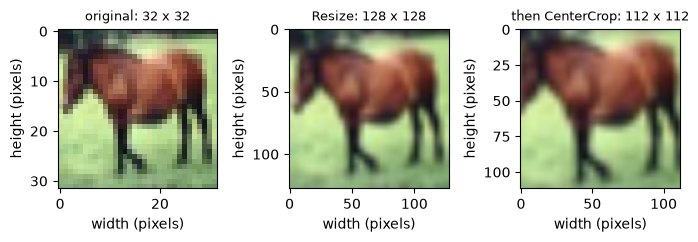

In [12]:
resized = T.Resize(IMG_SIZE)(img)                         # short side -> IMG_SIZE
cropped = T.CenterCrop(int(IMG_SIZE * 0.875))(resized)    # keep the centre (like 256 -> 224)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, im, title in zip(axes, [img, resized, cropped], ["original", "Resize", "then CenterCrop"]):
    ax.imshow(im)
    ax.set_title(f"{title}: {im.size[0]} x {im.size[1]}", fontsize=9)
    ax.set_xlabel("width (pixels)"); ax.set_ylabel("height (pixels)")
plt.tight_layout(); plt.show()

### Crop, squash or pad?

*Slide: "Crop, squash or pad?".*

CIFAR images are already square, so resizing them is easy. Real photos usually are not. To see the problem, we make a **non-square** image by placing two CIFAR images side by side, giving 64 × 32 pixels.

In [13]:
left_img, _ = raw_train[0]
right_img, _ = raw_train[1]
wide = Image.fromarray(np.concatenate([np.array(left_img), np.array(right_img)], axis=1))
print("non-square image size (W, H):", wide.size)

non-square image size (W, H): (64, 32)


For the "pad" option we need a small helper. `pad_to_square` adds a black border to the shorter side so that the width equals the height, using `T.functional.pad`. The `functional` module contains the plain functions behind the transform classes.

In [14]:
def pad_to_square(im, fill=0):
    """Pad a PIL image with a border so that width == height."""
    w, h = im.size
    side = max(w, h)
    left, top = (side - w) // 2, (side - h) // 2
    return T.functional.pad(im, [left, top, side - w - left, side - h - top], fill=fill)

print("padded size (W, H):", pad_to_square(wide).size)

padded size (W, H): (64, 64)


Now we compare the three ways of making the wide image square. Look at what each one keeps and what it loses.

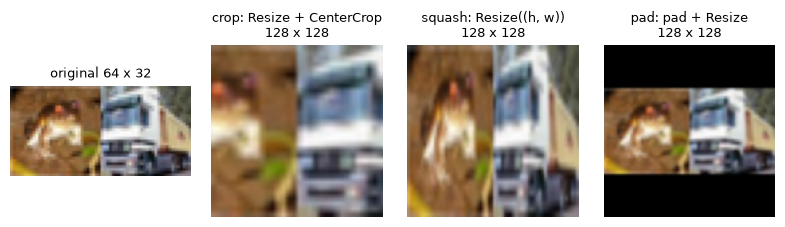

In [15]:
options = {
    "crop: Resize + CenterCrop": T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE)]),
    "squash: Resize((h, w))": T.Resize((IMG_SIZE, IMG_SIZE)),
    "pad: pad + Resize": T.Compose([pad_to_square, T.Resize(IMG_SIZE)]),
}
fig, axes = plt.subplots(1, 4, figsize=(8, 2.2))
axes[0].imshow(wide); axes[0].set_title(f"original {wide.size[0]} x {wide.size[1]}", fontsize=9)
for ax, (name, tf) in zip(axes[1:], options.items()):
    out = tf(wide)
    ax.imshow(out); ax.set_title(f"{name}\n{out.size[0]} x {out.size[1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

The trade-offs:

- **Crop** keeps the shapes undistorted but **throws away the edges**. Here it cut half of each image off. Fine when the object is in the centre.
- **Squash** keeps everything but **distorts shapes**: objects become thinner or fatter. Models can cope if training and test images are squashed the same way.
- **Pad** keeps everything undistorted but **wastes pixels** on empty borders, so the object ends up smaller.

### Step 4: normalise

*Slide: "Normalisation".*

`T.Normalize(mean, std)` shifts and scales each colour channel: `output = (input - mean) / std`. Afterwards each channel has roughly mean 0 and standard deviation 1, which helps training.

First, let's compute the per-channel mean and std of the CIFAR-10 training images. `raw_train.data` holds all 50,000 images as one NumPy array, so we can do it in a single vectorised step instead of a slow Python loop over images.

In [16]:
data = raw_train.data                                   # NumPy array [50000, 32, 32, 3], uint8
print("raw data:", data.shape, data.dtype)
pixels = torch.from_numpy(data).float().div_(255)       # all pixels as floats in [0, 1]
cifar_mean = pixels.mean(dim=(0, 1, 2))                 # average over images, rows and columns
cifar_std = pixels.std(dim=(0, 1, 2))
del pixels                                              # free about 600 MB of memory
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
print("CIFAR-10 mean:", cifar_mean.numpy().round(3), "| std:", cifar_std.numpy().round(3))
print("ImageNet mean:", IMAGENET_MEAN, "| std:", IMAGENET_STD)

raw data: (50000, 32, 32, 3) uint8


CIFAR-10 mean: [0.491 0.482 0.447] | std: [0.247 0.243 0.262]
ImageNet mean: [0.485, 0.456, 0.406] | std: [0.229, 0.224, 0.225]


The two sets of statistics are similar but not the same. Which should you use?

- With **ImageNet-pretrained weights**, use the **ImageNet** values. The model learned its features on inputs normalised that way, so we give it inputs that look the same.
- When **training from scratch**, use **your own dataset's** values.

We use pretrained weights, so we normalise with the ImageNet values. Watch how the value range changes: before, everything is in `[0, 1]`; afterwards values are centred around 0 and can be negative.

In [17]:
normalise = T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
t_norm = normalise(t)                         # t is the ToTensor() output from step 2
for name, x in [("before", t), ("after ", t_norm)]:
    print(f"{name}: shape {tuple(x.shape)} | min {x.min():.2f} | max {x.max():.2f} | mean {x.mean():.2f}")

before: shape (3, 32, 32) | min 0.04 | max 0.97 | mean 0.48
after : shape (3, 32, 32) | min -1.96 | max 2.31 | mean 0.13


### Step 5: `T.Compose`

`T.Compose` chains transforms into a single pipeline that is applied in order. This is our **test-time** pipeline: every step is deterministic, so the same image always produces the same tensor. `CenterCrop` does nothing for square CIFAR images, but keeps the pipeline safe for non-square ones.

In [18]:
test_tf = T.Compose([
    T.Resize(IMG_SIZE),                       # 32 x 32 -> IMG_SIZE x IMG_SIZE
    T.CenterCrop(IMG_SIZE),                   # no-op for square images, safe for others
    T.ToTensor(),                             # PIL [H, W, C] uint8 -> tensor [C, H, W] float in [0, 1]
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD), # ImageNet statistics (pretrained weights)
])
x = test_tf(img)
print(test_tf)
print("output:", tuple(x.shape), x.dtype, f"| range {x.min():.2f} to {x.max():.2f}")

Compose(
    Resize(size=128, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(128, 128))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
output: (3, 128, 128) torch.float32 | range -1.90 to 2.29


### Augmentation, illustrated

*Slide: "Data augmentation".*

**Data augmentation** creates slightly different versions of each training image on the fly: zoomed, flipped, rotated, with changed colours. The model sees a "new" image every epoch, which reduces overfitting. Below, the **same image** goes through the augmentation pipeline 8 times. Every call gives a different result, but the label stays the same: it is still the same object.

We use `scale=(0.6, 1.0)` in `RandomResizedCrop` so each crop keeps at least 60% of the image area. The default (8%) is designed for large ImageNet photos and would often crop a tiny CIFAR object away completely.

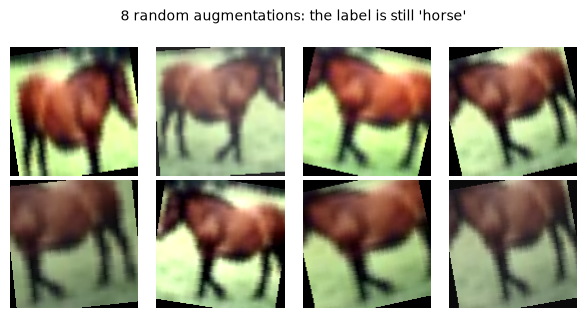

In [19]:
augment = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),   # random zoom + crop, then resize
    T.RandomHorizontalFlip(p=0.5),                     # mirror left-right half of the time
    T.RandomRotation(15),                              # rotate by up to +/- 15 degrees
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
])
fig, axes = plt.subplots(2, 4, figsize=(6, 3.2))
for ax in axes.flat:
    ax.imshow(augment(img))                            # a NEW random version on every call
    ax.axis("off")
fig.suptitle(f"8 random augmentations: the label is still '{classes[label]}'", fontsize=10)
plt.tight_layout(); plt.show()

### Training vs test transforms

The rule is simple: **augment the training set only.** Validation and test images must go through the deterministic `test_tf`, so that the scores measure the model and not the luck of the random transforms. Below are the two pipelines side by side. Calling `train_tf` twice on the same image gives two different tensors; `test_tf` always gives the same one.

In [20]:
train_tf = T.Compose([
    augment,                                  # random: training only
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print("train_tf:", train_tf, "\ntest_tf:", test_tf, sep="\n")
print("\nshapes: train", tuple(train_tf(img).shape), "| test", tuple(test_tf(img).shape))
print("two train_tf calls identical?", torch.equal(train_tf(img), train_tf(img)))
print("two test_tf calls identical? ", torch.equal(test_tf(img), test_tf(img)))

train_tf:
Compose(
    Compose(
    RandomResizedCrop(size=(128, 128), scale=(0.6, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=None)
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

test_tf:
Compose(
    Resize(size=128, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(128, 128))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

shapes: train (3, 128, 128) | test (3, 128, 128)
two train_tf calls identical? False
two test_tf calls identical?  True


### Best practice: choose augmentations that keep the label true

*Slide: "Augmentation: think about your data".*

An augmentation is only useful if the transformed image is still a realistic example of the **same class**.

- **For CIFAR-10**, horizontal flips are fine: a horse facing left is still a horse. Small rotations, crops and colour changes are also realistic for photos.
- **Vertical flips** would be a poor choice: upside-down ships and trucks almost never appear in the test set.
- **The same choice can be wrong elsewhere.** Recall the chest X-ray example from the lecture: a horizontal flip moves the heart to the right-hand side, producing an anatomically wrong image. A random crop can cut away the small region that shows the finding, so the "pneumonia" label no longer matches the image.

Always ask: *after this transform, would an expert still give the image the same label?*

### Key takeaways

- `ToTensor` converts PIL `[H, W, C]` uint8 (0–255) to a `[C, H, W]` float tensor (0–1).
- Resizing to the model's input size is required, but upscaling adds pixels, not detail. For non-square images choose between crop, squash and pad, knowing what each loses.
- Normalise with **ImageNet** statistics when using ImageNet-pretrained weights, and with your own dataset's statistics when training from scratch.
- Augment the **training** set only, and only with transforms that keep the label true.

### Try it yourself

1. Add `T.RandomVerticalFlip()` to `augment` and re-run the grid. Would this help or hurt on CIFAR-10?
2. Use `pad_to_square(wide, fill=128)`. What changes?
3. Compute the normalised tensor by hand: `(t - mean) / std` with the ImageNet values, and check it equals `t_norm`.

<details><summary>Solution</summary>

1. It produces upside-down images that never appear in the test set, so it would most likely hurt (or at best do nothing).
2. The border becomes grey (value 128) instead of black.
3. ```python
   mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
   std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
   print(torch.allclose((t - mean) / std, t_norm))   # True
   ```
   `.view(3, 1, 1)` makes the 3 values broadcast over every pixel of each channel.

</details>

## 3. Datasets & DataLoaders

*Lecture section 03: Datasets & DataLoaders.*

A **`Dataset`** knows how many items there are (`len(ds)`) and how to fetch item `i` (`ds[i]`), applying the transform as it goes. A **`DataLoader`** wraps a dataset and serves **batches**: it groups items, optionally shuffles them, and stacks them into one tensor.

### Loading CIFAR-10 with transforms

This time we pass a `transform`, so indexing returns a ready-to-use tensor instead of a PIL image. We create **two** training dataset objects over the same files: one with `train_tf` (for training) and one with `test_tf` (for validation). The reason becomes clear in a moment.

In [21]:
full_train_aug = datasets.CIFAR10(DATA_DIR, train=True, transform=train_tf)     # for training
full_train_plain = datasets.CIFAR10(DATA_DIR, train=True, transform=test_tf)    # for validation
test_full = datasets.CIFAR10(DATA_DIR, train=False, transform=test_tf)
print("training images:", len(full_train_plain), "| test images:", len(test_full))
print("classes:", full_train_plain.classes)
image, lbl = full_train_plain[0]             # indexing returns (image tensor, label int)
print("one item -> image:", tuple(image.shape), image.dtype, "| label:", lbl, "->", classes[lbl])

training images: 50000 | test images: 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
one item -> image: (3, 128, 128) torch.float32 | label: 6 -> frog


### Class distribution

Before training, always look at **how many examples each class has**. A bar chart makes it obvious. CIFAR-10 is perfectly **balanced** (5,000 training images per class). That is unusual: the chest X-ray data in the lecture was heavily imbalanced, which changes how you train and evaluate (see section 6).

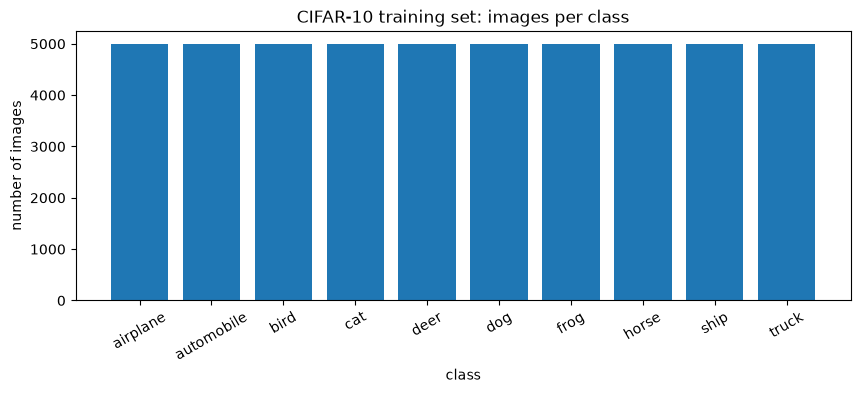

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


In [22]:
counts = np.bincount(raw_train.targets, minlength=10)
plt.figure(figsize=(10, 3.5))
plt.bar(classes, counts, color="tab:blue")
plt.title("CIFAR-10 training set: images per class")
plt.xlabel("class"); plt.ylabel("number of images")
plt.xticks(rotation=30)
plt.show()
print(dict(zip(classes, counts.tolist())))

### Making a validation split properly

*Slide: "Train / validation / test".*

We need a **validation set** to monitor training and choose settings, while keeping the **test set** untouched until the very end. We hold out 5,000 of the 50,000 training images.

The obvious tool, `random_split`, splits **one** dataset object. Because that object has `train_tf`, the validation images would also be randomly augmented, and our validation scores would be noisy and unrealistic. Instead, we shuffle the indices **once** and use them with `Subset` on our two dataset objects: training indices go to the augmented one, validation indices to the plain one. With `QUICK_RUN` we also keep only part of each split.

In [23]:
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(full_train_plain), generator=g).tolist()   # one shuffled list of indices
val_idx, train_idx = perm[:5000], perm[5000:]                         # 5k validation, 45k training
if TRAIN_SUBSET: train_idx = train_idx[:TRAIN_SUBSET]                 # QUICK_RUN: use fewer images
if VAL_SUBSET: val_idx = val_idx[:VAL_SUBSET]
train_set = Subset(full_train_aug, train_idx)      # training images, WITH augmentation
val_set = Subset(full_train_plain, val_idx)        # held-out images, NO augmentation
test_idx = torch.randperm(len(test_full), generator=g)[:TEST_SUBSET].tolist() if TEST_SUBSET else range(len(test_full))
test_set = Subset(test_full, test_idx)
print("train:", len(train_set), "| val:", len(val_set), "| test:", len(test_set))
print("images in both train and val:", len(set(train_idx) & set(val_idx)))

train: 5000 | val: 1000 | test: 2000
images in both train and val: 0


### DataLoaders

Now we wrap each set in a `DataLoader`. We use `shuffle=True` **only for training**: shuffling stops the model from learning the order of the data, while validation and test results don't depend on order, so we keep them fixed. One batch of images has shape `[N, C, H, W]` and the labels have shape `[N]`.

In [24]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          generator=torch.Generator().manual_seed(SEED))   # reproducible shuffling
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print("batches per epoch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

images, labels = next(iter(train_loader))     # grab one batch
print("images:", tuple(images.shape), images.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "e.g.", labels[:8].tolist())

batches per epoch -> train: 79 | val: 16 | test: 32
images: (64, 3, 128, 128) torch.float32
labels: (64,) torch.int64 e.g. [3, 0, 5, 4, 9, 4, 7, 9]


### Look at your data

*Slide: "Always look at your data".*

Before training anything, **look at a batch**. It catches many bugs: wrong labels, broken transforms, images that are all black. `make_grid` tiles a batch into one image.

The images are normalised, so their values are no longer in `[0, 1]` and the colours would look wrong. We first **un-normalise** them by reversing the formula: `x * std + mean`.

grid: (3, 132, 1042)


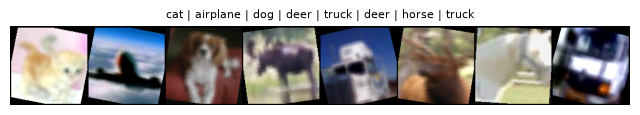

In [25]:
def denormalise(x):
    """Undo Normalize for plotting: x * std + mean, clipped to [0, 1]."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)

grid = make_grid(denormalise(images[:8]), nrow=8, padding=2)   # 8 images -> one [3, H, W] image
print("grid:", tuple(grid.shape))
plt.figure(figsize=(8, 1.4))
plt.imshow(grid.permute(1, 2, 0))                               # [C, H, W] -> [H, W, C]
plt.title(" | ".join(classes[l] for l in labels[:8]), fontsize=8)
plt.axis("off"); plt.show()

### Key takeaways

- A `Dataset` gives you `len(ds)` and `ds[i]`; a `DataLoader` turns it into shuffled batches of shape `[N, C, H, W]`.
- Check the class distribution first: CIFAR-10 is balanced, many real datasets are not.
- Make the validation split with shared indices and `Subset`, so validation images get the **test** transform, not the training augmentation.
- Shuffle the training loader only, and always look at a batch (un-normalised) before training.

### Try it yourself

1. Change `BATCH_SIZE` to 32 and re-run the DataLoader cell. How do `images.shape` and the number of batches change?
2. Plot 8 images from `val_loader` instead. Do you see any augmentation?
3. Why do we shuffle the indices with a seeded `Generator`?

<details><summary>Solution</summary>

1. `images.shape` becomes `[32, 3, 128, 128]` and there are about twice as many batches per epoch.
2. `imgs, lbls = next(iter(val_loader))`, then reuse the plotting code. There is no augmentation, because `val_set` uses `test_tf`.
3. So that the split is the same every time you run the notebook. Otherwise images could move between train and validation across runs, and results would not be comparable.

</details>

## 4. Pretrained models

*Lecture section 04: Pretrained models.*

Training a large CNN from scratch needs millions of images and many GPU hours. `torchvision.models` gives us networks that have already been trained on **ImageNet** (1.2 million photos, 1,000 classes). We just download the learned weights.

**ResNet-18 vs ResNet-50.** The slides use ResNet-50. Here we use the smaller **ResNet-18** so the notebook runs quickly on a laptop. The code is identical apart from the model name (`resnet50`, `ResNet50_Weights`) and the size of the final layer's input: **512** features for ResNet-18, **2048** for ResNet-50.

We load weights with the modern `weights=` argument. Older tutorials write `pretrained=True`; that form is deprecated, so don't copy it. Each weights object also carries its own **preprocessing** (`weights.transforms()`) and the list of **class names** (`weights.meta["categories"]`).

In [26]:
weights = ResNet18_Weights.DEFAULT            # the best available ImageNet weights
model = resnet18(weights=weights).to(device)  # downloads about 45 MB the first time
preprocess = weights.transforms()             # the exact preprocessing these weights expect
print(preprocess)
categories = weights.meta["categories"]
print(len(categories), "ImageNet classes, e.g.:", categories[:6])

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
1000 ImageNet classes, e.g.: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray']


### Making a prediction in five steps

*Slide: "Making a prediction".*

1. `model.eval()`: switch to **evaluation mode** (layers such as batch-norm and dropout behave differently in training).
2. **Preprocess** the image with `weights.transforms()`.
3. `unsqueeze(0)`: models expect a **batch**, so we turn `[3, H, W]` into `[1, 3, H, W]`.
4. **Forward pass** inside `torch.no_grad()`: we are not training, so PyTorch does not need to remember anything for gradients. This is faster and uses less memory.
5. `softmax` turns the 1,000 raw scores (**logits**) into probabilities, and `topk` keeps the most likely classes.

In [27]:
model.eval()                                       # 1. evaluation mode
pil_img, true_label = raw_test[0]
x = preprocess(pil_img)                            # 2. preprocess
print("after preprocess:", tuple(x.shape))
x = x.unsqueeze(0).to(device)                      # 3. add batch dim, move to device
print("after unsqueeze :", tuple(x.shape))
with torch.no_grad():                              # 4. forward pass without gradients
    logits = model(x)
print("logits:", tuple(logits.shape))
top_p, top_i = torch.softmax(logits, dim=1).topk(3)   # 5. probabilities -> top 3
for p, i in zip(top_p[0].tolist(), top_i[0].tolist()):
    print(f"   {categories[i]:<22s} {p:.1%}")
print("true CIFAR-10 label:", classes[true_label])

after preprocess: (3, 224, 224)
after unsqueeze : (1, 3, 224, 224)


logits: (1, 1000)
   fox squirrel           13.3%
   triceratops            10.3%
   moving van             4.9%
true CIFAR-10 label: cat


Let's do the same for a few more test images and show the top-3 **ImageNet** predictions above each one.

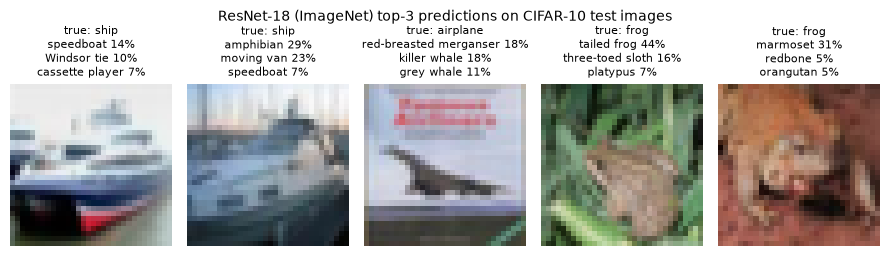

In [28]:
fig, axes = plt.subplots(1, 5, figsize=(9, 2.8))
for ax, idx in zip(axes, [1, 2, 3, 4, 5]):
    pil_img, true_label = raw_test[idx]
    with torch.no_grad():
        probs = torch.softmax(model(preprocess(pil_img).unsqueeze(0).to(device)), dim=1)
    top_p, top_i = probs.topk(3)
    lines = [f"{categories[i]} {p:.0%}" for p, i in zip(top_p[0].tolist(), top_i[0].tolist())]
    ax.imshow(pil_img); ax.axis("off")
    ax.set_title(f"true: {classes[true_label]}\n" + "\n".join(lines), fontsize=8)
fig.suptitle("ResNet-18 (ImageNet) top-3 predictions on CIFAR-10 test images", fontsize=10)
plt.tight_layout(); plt.show()

### What do we see?

Look at the predictions above. Two things stand out:

- **The labels are ImageNet's, not CIFAR's.** ImageNet has 1,000 fine-grained classes such as "airliner", "tabby" or "container ship". The model has no output called simply "cat" or "airplane", so even a sensible guess does not match our 10 labels.
- **Tiny, upscaled images are hard.** `weights.transforms()` blows each 32 × 32 image up to 224 × 224, so the model sees blurry inputs very unlike its sharp training photos. Some predictions are confident and plausible, others are clearly wrong.

The features the network has learned (edges, textures, shapes) are still useful. We just need a new final layer that maps them to **our** 10 classes. That is **transfer learning**.

### Peek inside

`print(model)` lists every layer. Scroll through it: a first convolution (`conv1`), four groups of residual blocks (`layer1` to `layer4`), a pooling layer, and a final fully connected layer `fc` that maps 512 features to 1,000 ImageNet classes. That last layer is the one we will replace.

In [29]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

Now the final layer on its own, and the total number of **parameters** (learned weights). `p.numel()` counts the numbers in one weight tensor; we add them all up.

In [30]:
print("final layer:", model.fc)
print("fc input features:", model.fc.in_features, "(ResNet-50: 2048)")
n_params = sum(p.numel() for p in model.parameters())
print(f"total parameters: {n_params:,}")

final layer: Linear(in_features=512, out_features=1000, bias=True)
fc input features: 512 (ResNet-50: 2048)
total parameters: 11,689,512


### Key takeaways

- Load pretrained models with `weights=...` (e.g. `ResNet18_Weights.DEFAULT`), never the deprecated `pretrained=True`.
- The weights object provides the matching preprocessing (`weights.transforms()`) and the class names (`weights.meta["categories"]`).
- Prediction = `eval()` → preprocess → `unsqueeze(0)` → forward pass in `no_grad()` → `softmax` + `topk`.
- An ImageNet model predicts ImageNet classes; to use it for CIFAR-10 we must replace its final `fc` layer.

### Try it yourself

1. Print the top-5 predictions for `raw_test[0]` instead of the top 3.
2. How many parameters are in `model.fc` alone? What fraction of the total is that?
3. Which line(s) would change to use ResNet-50?

<details><summary>Solution</summary>

1. Replace `.topk(3)` with `.topk(5)` in the five-step cell.
2. `sum(p.numel() for p in model.fc.parameters())` gives 513,000 (512 × 1000 weights + 1000 biases), about 4.4% of the 11.7 million total.
3. `from torchvision.models import resnet50, ResNet50_Weights` and `model = resnet50(weights=ResNet50_Weights.DEFAULT)`. `model.fc.in_features` becomes 2048.

</details>

## 5. Transfer learning

*Lecture section 05: Transfer learning.*

The idea: **keep the backbone, replace the head.** The early and middle layers of an ImageNet model detect general visual patterns that are useful for almost any image task. Only the final layer is specific to ImageNet's 1,000 classes.

```
 input image                                                    output
 [N, 3, 128, 128]                                               [N, 10]
      │                                                            ▲
      ▼                                                            │
 ┌──────────────────────────────────────────────┐   ┌──────────────────────┐
 │  BACKBONE (pretrained on ImageNet)           │   │  NEW HEAD            │
 │  conv1 → layer1 → layer2 → layer3 → layer4   │──▶│  fc: 512 → 10        │
 │  → avgpool        (keep these weights)       │   │  (trained from zero) │
 └──────────────────────────────────────────────┘   └──────────────────────┘
          512 features per image
```

We will try two strategies:

1. **Feature extraction**: freeze the whole backbone and train only the new head.
2. **Fine-tuning**: also unfreeze the last block of the backbone (`layer4`) and train it gently.

### Strategy 1: feature extraction

Setting `requires_grad = False` on a parameter **freezes** it: the optimiser will not change it. We freeze every parameter, then replace `model.fc` with a new `nn.Linear` layer with 10 outputs. New layers are trainable by default. The small helper `count_params` shows how few parameters are left to train.

In [31]:
def count_params(m):
    """Return (trainable, frozen) parameter counts."""
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return trainable, sum(p.numel() for p in m.parameters()) - trainable

set_seed(SEED)
model = resnet18(weights=ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                        # freeze the whole backbone
model.fc = nn.Linear(model.fc.in_features, 10)     # new head: 512 -> 10 CIFAR classes (trainable)
model = model.to(device)
trainable, frozen = count_params(model)
print(f"trainable: {trainable:,} | frozen: {frozen:,}")

trainable: 5,130 | frozen: 11,176,512


We will need this "pretrained backbone + new head" model several more times, so we wrap the same steps in a function, `build_model`.

In [32]:
def build_model(num_classes=10):
    """ResNet-18 with ImageNet weights, a frozen backbone and a new trainable head."""
    m = resnet18(weights=ResNet18_Weights.DEFAULT)
    for p in m.parameters():
        p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(device)

### The training loop

*Slide: "The training loop".*

Training repeats five steps for every batch:

1. `optimizer.zero_grad()`: clear the gradients from the previous batch (PyTorch adds them up otherwise).
2. **Forward pass**: `outputs = model(images)` gives one score per class.
3. **Loss**: `criterion(outputs, labels)` measures how wrong the scores are. For classification we use **cross-entropy**.
4. `loss.backward()`: compute the gradient of the loss for every trainable parameter (**backpropagation**).
5. `optimizer.step()`: nudge each parameter a little in the direction that lowers the loss.

`model.train()` and `model.eval()` switch layers such as batch-norm and dropout between their training and evaluation behaviour. Always call `train()` before training and `eval()` before evaluating. One pass through all the training data is called an **epoch**.

In [33]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()                                    # training mode
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in tqdm(loader, desc="train", leave=False, mininterval=1):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()                        # 1. clear old gradients
        outputs = model(images)                      # 2. forward pass
        loss = criterion(outputs, labels)            # 3. compute the loss
        loss.backward()                              # 4. backpropagate
        optimizer.step()                             # 5. update the weights
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += labels.size(0)
    return total_loss / n, correct / n               # average loss, accuracy

`evaluate` is the same loop without steps 1, 4 and 5: no gradients and no weight updates. The `@torch.no_grad()` line above the function switches gradient tracking off for the whole function. It returns the average loss and the accuracy.

In [34]:
@torch.no_grad()                                     # no gradients needed for evaluation
def evaluate(model, loader, criterion):
    model.eval()                                     # evaluation mode
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        total_loss += criterion(outputs, labels).item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += labels.size(0)
    return total_loss / n, correct / n

Two more helpers: `fit` runs several epochs, evaluating on the validation set after each one and recording the results in a `history` dictionary; `plot_history` draws the **learning curves** (loss and accuracy per epoch).

In [35]:
def fit(model, optimizer, epochs, criterion):
    """Train for some epochs; return the history and the time taken in seconds."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        for key, value in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[key].append(value)
        print(f"epoch {epoch}: train loss {tr_loss:.3f}, acc {tr_acc:.1%} | val loss {va_loss:.3f}, acc {va_acc:.1%}")
    return history, time.perf_counter() - start

`plot_history` takes that dictionary and draws two charts side by side: loss on the left, accuracy on the right, each with a training and a validation line.

In [36]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(epochs, history[f"train_{metric}"], "o-", label="train")
        ax.plot(epochs, history[f"val_{metric}"], "o-", label="validation")
        ax.set_title(f"{title}: {'loss' if metric == 'loss' else 'accuracy'}")
        ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.legend()
        ax.set_xticks(list(epochs))
    plt.tight_layout(); plt.show()

### Training the head

We use the **Adam** optimiser with learning rate `1e-3`, and give it **only the head's parameters** (`model.fc.parameters()`): the frozen backbone has nothing to learn. The progress bar shows each epoch's batches. Training accuracy is measured on augmented images while the model is still learning, so it can be lower than validation accuracy early on.

In [37]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)   # only the head is optimised
set_seed(SEED)
hist_head, time_head = fit(model, optimizer, EPOCHS_HEAD, criterion)
print(f"training time: {time_head:.0f} s")

train:   0%|          | 0/79 [00:00<?, ?it/s]

train:   1%|▏         | 1/79 [00:01<02:29,  1.91s/it]

train:  23%|██▎       | 18/79 [00:02<00:08,  7.55it/s]

train:  44%|████▍     | 35/79 [00:03<00:03, 11.08it/s]

train:  67%|██████▋   | 53/79 [00:04<00:01, 13.25it/s]

train:  89%|████████▊ | 70/79 [00:05<00:00, 14.47it/s]

... (3 outputs left out)

train:  46%|████▌     | 36/79 [00:02<00:02, 17.24it/s]

train:  68%|██████▊   | 54/79 [00:03<00:01, 16.81it/s]

train:  90%|████████▉ | 71/79 [00:04<00:00, 16.26it/s]

epoch 2: train loss 1.323, acc 56.5% | val loss 1.168, acc 62.3%
training time: 14 s


Now the learning curves for Strategy 1. Both losses should go down and both accuracies up. With only a frozen backbone and a small linear head, the gap between training and validation stays small.

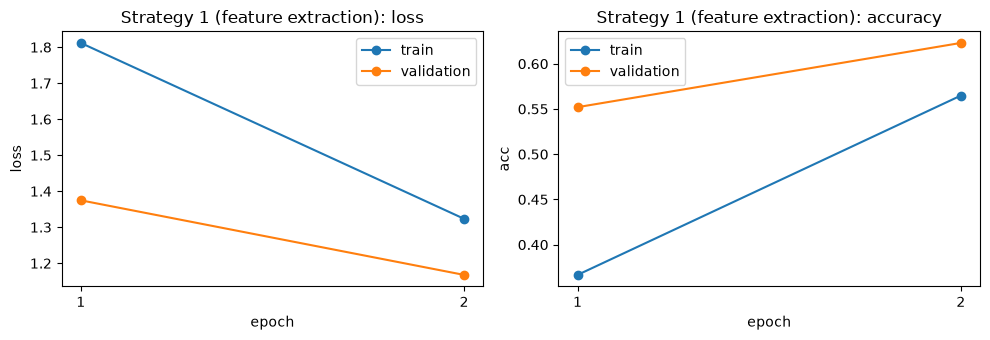

In [38]:
plot_history(hist_head, "Strategy 1 (feature extraction)")

### Strategy 2: fine-tuning

Now we start from the trained head and **unfreeze `layer4`**, the last block of the backbone. Its features are the most ImageNet-specific, so adapting them to CIFAR-10 helps most.

We give the optimiser **two parameter groups** with different learning rates. `layer4` already holds good pretrained weights, so it gets a **small** learning rate (`1e-4`) to adjust them gently instead of destroying them. The head gets the usual `1e-3`. First we save a copy of the Strategy 1 weights, so we can compare and keep the better one.

In [39]:
head_state = copy.deepcopy(model.state_dict())       # keep the Strategy 1 weights
for p in model.layer4.parameters():
    p.requires_grad = True                           # unfreeze the last residual block
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},   # pretrained layers: small steps
    {"params": model.fc.parameters(), "lr": 1e-3},       # new head: larger steps
])
trainable_ft, frozen_ft = count_params(model)
print(f"trainable: {trainable_ft:,} | frozen: {frozen_ft:,}")

trainable: 8,398,858 | frozen: 2,782,784


Training is slower now, because gradients have to flow back through `layer4` as well.

train:   0%|          | 0/79 [00:00<?, ?it/s]

train:  10%|█         | 8/79 [00:01<00:08,  7.91it/s]

train:  30%|███       | 24/79 [00:02<00:04, 12.30it/s]

train:  51%|█████     | 40/79 [00:03<00:02, 13.69it/s]

train:  70%|██████▉   | 55/79 [00:04<00:01, 14.13it/s]

train:  89%|████████▊ | 70/79 [00:05<00:00, 14.20it/s]

... (4 outputs left out)

train:  59%|█████▉    | 47/79 [00:03<00:02, 14.93it/s]

train:  80%|███████▉  | 63/79 [00:04<00:01, 14.99it/s]

train:  99%|█████████▊| 78/79 [00:05<00:00, 14.98it/s]

epoch 2: train loss 0.692, acc 76.0% | val loss 0.496, acc 82.6%
training time: 13 s


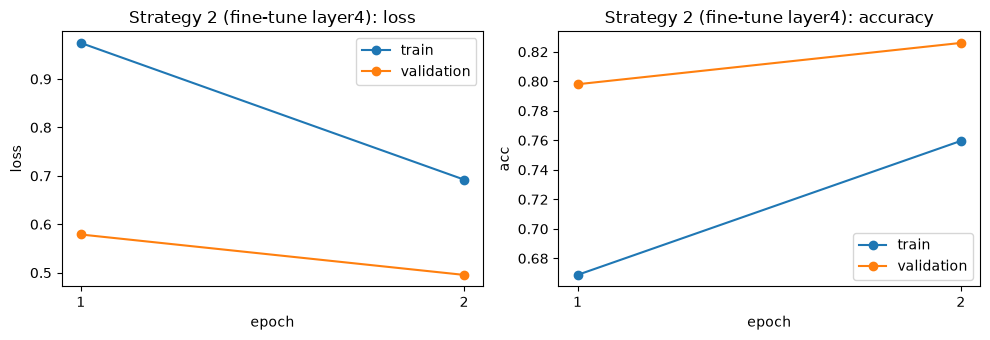

In [40]:
hist_ft, time_ft = fit(model, optimizer, EPOCHS_FINETUNE, criterion)
print(f"training time: {time_ft:.0f} s")
plot_history(hist_ft, "Strategy 2 (fine-tune layer4)")

### Comparing the two strategies

The table below is computed from this run. Validation accuracy is taken after the last epoch of each strategy. Remember that Strategy 2 started from the trained Strategy 1 head, so it also benefits from that earlier training. Treat small timing differences with care: the very first training epoch also pays one-off start-up costs (for example GPU warm-up), which can make Strategy 1 look slower than it really is.

In [41]:
rows = [("1: feature extraction", hist_head["val_acc"][-1], time_head, trainable),
        ("2: fine-tune layer4", hist_ft["val_acc"][-1], time_ft, trainable_ft)]
print(f"{'strategy':<24}{'val accuracy':>14}{'train time (s)':>16}{'trainable params':>18}")
for name, acc, secs, n in rows:
    print(f"{name:<24}{acc:>14.1%}{secs:>16.0f}{n:>18,}")

strategy                  val accuracy  train time (s)  trainable params
1: feature extraction            62.3%              14             5,130
2: fine-tune layer4              82.6%              13         8,398,858


### Which strategy should you use?

*Slide: "Which strategy?".* A rule of thumb based on two questions: **how much data do you have**, and **how similar is it to ImageNet**?

| | Similar to ImageNet | Very different (e.g. X-rays, satellite images) |
|---|---|---|
| **Small dataset** | Feature extraction: train only the head | Fine-tune the last few blocks, carefully, with strong augmentation |
| **Large dataset** | Fine-tune the later blocks (or everything) | Fine-tune everything, or even train from scratch |

The less data you have, the fewer parameters you should train, because many trainable parameters on little data leads to overfitting.

### Saving and loading a model

*Slide: "Saving and loading".*

The recommended way to save a PyTorch model is to save its **`state_dict`**: a dictionary of all its weight tensors. To load it, you first **build the same architecture** in code, then copy the weights in with `load_state_dict`. We save whichever strategy gave the higher validation accuracy, reload it into a fresh model, and check it scores the same.

In [42]:
use_ft = hist_ft["val_acc"][-1] >= hist_head["val_acc"][-1]
best_state = model.state_dict() if use_ft else head_state
torch.save(best_state, "cifar10_resnet18_best.pt")         # only the weights (a dict of tensors)
print("saved the Strategy", 2 if use_ft else 1, "weights")

best_model = build_model()                                  # fresh model with the same architecture
best_model.load_state_dict(torch.load("cifar10_resnet18_best.pt", map_location=device))
_, reloaded_acc = evaluate(best_model, val_loader, criterion)
print(f"reloaded model, validation accuracy: {reloaded_acc:.1%}")

saved the Strategy 2 weights


reloaded model, validation accuracy: 82.6%


### Key takeaways

- Transfer learning = keep the pretrained backbone, replace the head (`model.fc`) with a new layer for your classes.
- Freeze parameters with `requires_grad = False`; pass only trainable parameters to the optimiser.
- The training loop is always: `zero_grad` → forward → loss → `backward` → `step`; use `model.train()` / `model.eval()` and `torch.no_grad()` for evaluation.
- Fine-tuning pretrained layers needs a **smaller** learning rate than the new head; parameter groups let you do both in one optimiser.
- Save the `state_dict`, and load it into a freshly built model with the same architecture.

### Try it yourself

1. Also unfreeze `layer3` (learning rate `1e-5`) and fine-tune for one more epoch. Does validation accuracy improve?
2. Train Strategy 1 with `lr=1e-2` instead of `1e-3`. What happens to the curves?
3. What would go wrong if you called `torch.load` on the file and used the result directly as a model?

<details><summary>Solution</summary>

1. ```python
   for p in model.layer3.parameters():
       p.requires_grad = True
   optimizer = torch.optim.Adam([
       {"params": model.layer3.parameters(), "lr": 1e-5},
       {"params": model.layer4.parameters(), "lr": 1e-4},
       {"params": model.fc.parameters(), "lr": 1e-3}])
   fit(model, optimizer, 1, criterion)
   ```
   With the small quick-run subset the gain is usually small; it helps more with more data.
2. The loss typically drops faster at first but is noisier, and validation accuracy can bounce around.
3. `torch.load` returns a plain dictionary of tensors, not a model: it has no `forward` method. You need `build_model()` and then `load_state_dict(...)`.

</details>

## 6. Evaluating properly

*Lecture section 06: Evaluating properly.*

So far we have only looked at validation accuracy. Now we evaluate the saved best model **once** on the **test set**, which it has never seen, and look at the results in more detail.

### Collecting predictions

`predict` runs the model over a loader and collects the predicted class (`argmax` of the scores) and the true label for every image. `.cpu()` moves results off the GPU so NumPy and scikit-learn can use them.

In [43]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, targets = [], []
    for images, labels in loader:
        preds.append(model(images.to(device)).argmax(1).cpu())
        targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

y_pred, y_true = predict(best_model, test_loader)
print("predictions:", y_pred.shape, "| labels:", y_true.shape)
print(f"test accuracy: {(y_pred == y_true).mean():.1%}")

predictions: (2000,) | labels: (2000,)
test accuracy: 81.5%


### Confusion matrix

*Slide: "Confusion matrix".*

A **confusion matrix** counts, for every true class (row), how often the model predicted each class (column). The diagonal holds the correct predictions; everything off the diagonal is a mistake, and its position tells you *which* mistake.

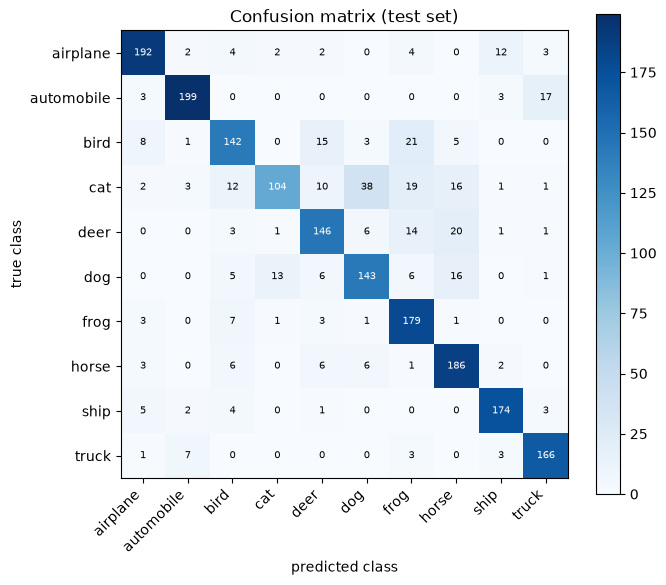

In [44]:
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), classes, rotation=45, ha="right"); ax.set_yticks(range(10), classes)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title("Confusion matrix (test set)")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

### Classification report

*Slide: "Precision, recall, F1".*

`classification_report` gives three numbers per class:

- **Precision**: of the images the model *called* "cat", how many really were cats?
- **Recall**: of the *real* cats, how many did the model find?
- **F1**: a single score that balances precision and recall (their harmonic mean).

`support` is the number of test images of that class.

In [45]:
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

              precision    recall  f1-score   support

    airplane      0.885     0.869     0.877       221
  automobile      0.930     0.896     0.913       222
        bird      0.776     0.728     0.751       195
         cat      0.860     0.505     0.636       206
        deer      0.772     0.760     0.766       192
         dog      0.726     0.753     0.739       190
        frog      0.725     0.918     0.810       195
       horse      0.762     0.886     0.819       210
        ship      0.888     0.921     0.904       189
       truck      0.865     0.922     0.892       180

    accuracy                          0.816      2000
   macro avg      0.819     0.816     0.811      2000
weighted avg      0.821     0.816     0.812      2000



### Per-class accuracy and common confusions

Per-class accuracy is the diagonal of the confusion matrix divided by each row's total (the same as recall). Below we sort the classes from worst to best and list the five most frequent mistakes. Typically the animal classes are hardest, especially **cat vs dog**, and vehicles get mixed up with each other (**automobile vs truck**, **airplane vs ship**). At 32 × 32 pixels these pairs share colours, shapes and backgrounds (sky and sea are both blue), so this is understandable. Compare the list with your own output.

In [46]:
per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(classes, per_class), key=lambda t: t[1]):
    print(f"{name:<11s} {acc:.1%}")

mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)                    # keep only the errors
print("\nMost common mistakes (true -> predicted):")
for k in np.argsort(mistakes, axis=None)[::-1][:5]:
    i, j = divmod(k, 10)
    print(f"   {classes[i]} -> {classes[j]}: {mistakes[i, j]} images")

cat         50.5%
bird        72.8%
dog         75.3%
deer        76.0%
airplane    86.9%
horse       88.6%
automobile  89.6%
frog        91.8%
ship        92.1%
truck       92.2%

Most common mistakes (true -> predicted):
   cat -> dog: 38 images
   bird -> frog: 21 images
   deer -> horse: 20 images
   cat -> frog: 19 images
   automobile -> truck: 17 images


### Looking at the mistakes

Numbers only tell part of the story. Looking at **misclassified images** often shows *why* the model fails: odd viewpoints, cluttered backgrounds, objects cut off, or even labels that seem wrong.

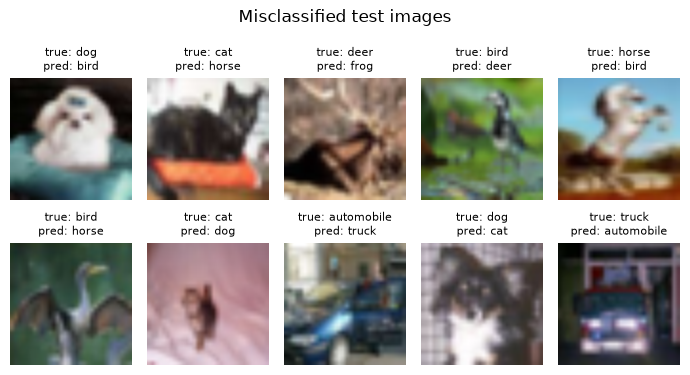

In [47]:
wrong = np.flatnonzero(y_pred != y_true)[:10]    # the first 10 mistakes
fig, axes = plt.subplots(2, 5, figsize=(7, 4))
for ax, i in zip(axes.flat, wrong):
    image, _ = test_set[i]
    ax.imshow(denormalise(image).permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]}", fontsize=8)
fig.suptitle("Misclassified test images")
plt.tight_layout(); plt.show()

### Accuracy is not enough: an imbalanced mini-experiment

*Slide: "Accuracy is not enough".*

CIFAR-10 is balanced, so accuracy is a fair summary. Many real datasets are not. To see why that matters, we build a small **2-class** dataset from the test set with a deliberate **1 : 3 imbalance**: 300 cats (the minority class) and 900 dogs.

In [48]:
test_labels = np.array(raw_test.targets)
cat_idx = np.flatnonzero(test_labels == classes.index("cat"))[:300]   # minority: 300 cats
dog_idx = np.flatnonzero(test_labels == classes.index("dog"))[:900]   # majority: 900 dogs
y_bin = np.array([0] * len(cat_idx) + [1] * len(dog_idx))             # 0 = cat, 1 = dog
print("cats:", (y_bin == 0).sum(), "| dogs:", (y_bin == 1).sum())

cats: 300 | dogs: 900


Now a "model" that ignores the image completely and **always predicts the majority class** ("dog"). Its accuracy looks respectable, but its **recall on cats is 0%**: it never finds a single cat. Accuracy hides this because cats are only a quarter of the data.

In [49]:
from sklearn.metrics import accuracy_score, recall_score
y_base = np.ones_like(y_bin)                     # "always say dog"
print(f"accuracy  : {accuracy_score(y_bin, y_base):.1%}")
print(f"cat recall: {recall_score(y_bin, y_base, pos_label=0):.1%}")
print(f"dog recall: {recall_score(y_bin, y_base, pos_label=1):.1%}")

accuracy  : 75.0%
cat recall: 0.0%
dog recall: 100.0%


### Two fixes for imbalance

*Slide: "Handling class imbalance".*

**Fix 1: class weights.** Tell the loss function that mistakes on the rare class cost more. A common choice is `weight = total / (number_of_classes × class_count)`, so the rare class gets a weight above 1 and the common class a weight below 1. We pass the weights to `nn.CrossEntropyLoss(weight=...)`.

In [50]:
counts_bin = np.bincount(y_bin)                                   # [n_cats, n_dogs]
class_weights = torch.tensor(len(y_bin) / (2 * counts_bin), dtype=torch.float32)
print("counts:", counts_bin, "| class weights:", class_weights.numpy().round(3))
weighted_criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
print(weighted_criterion)

counts: [300 900] | class weights: [2.    0.667]
CrossEntropyLoss()


**Fix 2: oversampling with `WeightedRandomSampler`.** Instead of changing the loss, change **which images the model sees**. Each image gets a sampling weight of `1 / (count of its class)`, so the sampler draws cats more often and each epoch looks balanced. Below we count the labels the sampler would draw in one epoch. A sampler replaces `shuffle=True` in the `DataLoader`. (Training a cat/dog model with either fix is left as an optional exercise.)

In [51]:
sample_weights = torch.as_tensor(1.0 / counts_bin[y_bin], dtype=torch.double)  # rare -> bigger
sampler = WeightedRandomSampler(sample_weights, num_samples=len(y_bin), replacement=True,
                                generator=torch.Generator().manual_seed(SEED))
drawn = y_bin[list(sampler)]                      # labels of the images one epoch would use
print(f"original  -> cats: {(y_bin == 0).sum()}, dogs: {(y_bin == 1).sum()}")
print(f"resampled -> cats: {(drawn == 0).sum()}, dogs: {(drawn == 1).sum()}")

cat_dog_set = Subset(test_full, np.concatenate([cat_idx, dog_idx]).tolist())   # labels here are 3 and 5
cat_dog_loader = DataLoader(cat_dog_set, batch_size=BATCH_SIZE, sampler=sampler)
print("loader with sampler:", len(cat_dog_loader), "batches per epoch")

original  -> cats: 300, dogs: 900
resampled -> cats: 608, dogs: 592
loader with sampler: 19 batches per epoch


### Back to the chest X-rays

In the lecture's chest X-ray example, the two kinds of mistake have very different costs:

- **Sensitivity** (recall on the disease class): of the patients who *have* pneumonia, how many do we detect? A missed case (false negative) can mean a sick patient is sent home.
- **Specificity** (recall on the healthy class): of the *healthy* patients, how many do we correctly clear? A false alarm (false positive) means extra tests and worry, but is usually less harmful.

An "always healthy" model on imbalanced data could score high accuracy with **0% sensitivity**, exactly like our "always dog" baseline. That's why medical models are judged on sensitivity, specificity and the confusion matrix, not on accuracy alone. Decide which mistakes matter most **before** you choose your metric.

### Key takeaways

- Evaluate on the **test set once**, at the end, with a model chosen using the validation set.
- The confusion matrix shows *which* classes get confused; precision, recall and F1 summarise each class.
- Look at misclassified images: they often explain the numbers.
- On imbalanced data, accuracy can look good while the minority class is ignored. Use per-class recall, class weights or a `WeightedRandomSampler`.

### Try it yourself

1. Which class has the lowest recall in your run? Look at its row of the confusion matrix: which class does it get confused with most?
2. For the "always dog" baseline, compute the **precision** for dogs. Why is it exactly 75%?
3. Change the imbalance to 1 : 9 (100 cats, 900 dogs). What accuracy does the baseline get now?

<details><summary>Solution</summary>

1. Read it from the sorted per-class list; the "most common mistakes" list shows its main confusion.
2. `precision_score(y_bin, y_base, pos_label=1)` (import it from `sklearn.metrics`). Every image is called "dog" and 900 of the 1,200 really are dogs, so 900 / 1200 = 75%.
3. Use `[:100]` for `cat_idx`. The baseline accuracy becomes 900 / 1000 = 90%, still with 0% cat recall: the more imbalanced the data, the more misleading accuracy becomes.

</details>

## 7. Best practices & hyperparameter tuning

*Lecture section 07: Best practices & hyperparameter tuning.*

### Parameters vs hyperparameters

- **Parameters** are the weights the model **learns** during training (the convolution filters, the `fc` weights, ...). There are millions of them and the optimiser sets them.
- **Hyperparameters** are the settings **you choose** before training: learning rate, batch size, number of epochs, image size, which layers to freeze, the augmentations. The optimiser cannot learn them; you choose them by experiment, using the **validation** set.

The cell below counts the parameters in each part of our fine-tuned model and lists some of the hyperparameters we chose.

In [52]:
print("Parameters (learned by training):")
for name, child in model.named_children():
    n = sum(p.numel() for p in child.parameters())
    if n:
        print(f"   {name:<7s} {n:>12,}")
print(f"   {'total':<7s} {sum(p.numel() for p in model.parameters()):>12,}")
print("\nHyperparameters (chosen by us):")
print(f"   lr head=1e-3, lr layer4=1e-4, BATCH_SIZE={BATCH_SIZE}, IMG_SIZE={IMG_SIZE}, "
      f"EPOCHS_HEAD={EPOCHS_HEAD}, EPOCHS_FINETUNE={EPOCHS_FINETUNE}")

Parameters (learned by training):
   conv1          9,408
   bn1              128
   layer1       147,968
   layer2       525,568
   layer3     2,099,712
   layer4     8,393,728
   fc             5,130
   total     11,181,642

Hyperparameters (chosen by us):
   lr head=1e-3, lr layer4=1e-4, BATCH_SIZE=64, IMG_SIZE=128, EPOCHS_HEAD=2, EPOCHS_FINETUNE=2


### Sanity check: overfit one batch

*Slide: "Sanity check: overfit a single batch".*

Before a long training run, check that your model **can learn at all**. Take one small batch (32 images) and train on it again and again. A working model should **memorise** it: the loss should fall towards zero. If it doesn't, there is a bug, for example the wrong labels, a frozen layer that should be trainable, or a missing `optimizer.step()`. This takes seconds and can save hours.

In [53]:
set_seed(SEED)
tiny_model = build_model()
tiny_images, tiny_labels = next(iter(train_loader))
tiny_images, tiny_labels = tiny_images[:32].to(device), tiny_labels[:32].to(device)   # one fixed batch
opt = torch.optim.Adam(tiny_model.fc.parameters(), lr=1e-2)
tiny_model.train()
tiny_losses = []
for step in range(50):
    opt.zero_grad()
    loss = criterion(tiny_model(tiny_images), tiny_labels)
    loss.backward(); opt.step()
    tiny_losses.append(loss.item())
print(f"loss: step 1 = {tiny_losses[0]:.3f} -> step 50 = {tiny_losses[-1]:.4f}")

loss: step 1 = 2.598 -> step 50 = 0.0001


Plotting the loss for each step makes the check easy to read at a glance: a curve that heads towards zero means the model, the loss and the optimiser are wired up correctly.

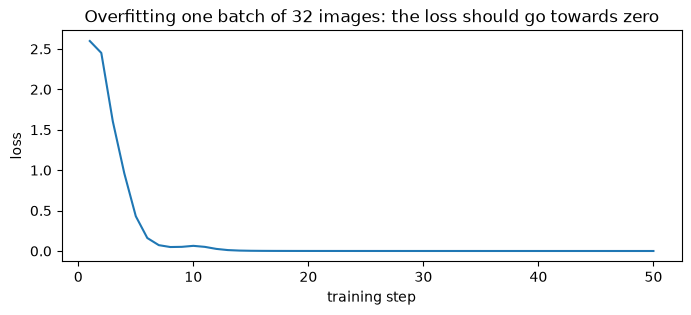

In [54]:
plt.figure(figsize=(8, 3))
plt.plot(range(1, 51), tiny_losses)
plt.title("Overfitting one batch of 32 images: the loss should go towards zero")
plt.xlabel("training step"); plt.ylabel("loss")
plt.show()

### Learning rate comparison

*Slide: "The learning rate".*

The **learning rate** is usually the most important hyperparameter. We train a fresh head for one short epoch (on 2,000 training images) at four learning rates, `1e-4` to `1e-1`, and plot the training loss after every batch (on a log scale, so all four curves fit):

- **Too low**: the loss falls very slowly. Training works but wastes time.
- **About right**: the loss falls quickly and steadily.
- **Too high**: the loss jumps around instead of falling smoothly, because each step overshoots the minimum. Much too high and the loss shoots **up** and stays far above the others.

Good learning rates span several orders of magnitude, so we search on a **log scale** (`1e-4`, `1e-3`, `1e-2`, ...) rather than `0.001`, `0.002`, `0.003`.

In [55]:
small_train_loader = DataLoader(Subset(full_train_aug, train_idx[:2000]), batch_size=BATCH_SIZE,
                                shuffle=True, num_workers=NUM_WORKERS)
lr_curves = {}
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    set_seed(SEED)
    m = build_model()
    opt = torch.optim.Adam(m.fc.parameters(), lr=lr)
    m.train(); lr_curves[lr] = []
    for imgs, lbls in tqdm(small_train_loader, desc=f"lr={lr:g}", leave=False, mininterval=1):
        opt.zero_grad()
        loss = criterion(m(imgs.to(device)), lbls.to(device))
        loss.backward(); opt.step()
        lr_curves[lr].append(loss.item())

lr=0.0001:   0%|          | 0/32 [00:00<?, ?it/s]

lr=0.0001:  56%|█████▋    | 18/32 [00:01<00:00, 17.02it/s]

lr=0.001:   0%|          | 0/32 [00:00<?, ?it/s]

lr=0.001:  53%|█████▎    | 17/32 [00:01<00:00, 16.47it/s]

lr=0.01:   0%|          | 0/32 [00:00<?, ?it/s]

lr=0.01:  53%|█████▎    | 17/32 [00:01<00:00, 16.55it/s]

lr=0.1:   0%|          | 0/32 [00:00<?, ?it/s]

lr=0.1:  53%|█████▎    | 17/32 [00:01<00:00, 16.89it/s]

Now all curves on one chart. Match each learning rate to one of the three patterns described above: which is too low, which is about right, and which are too high?

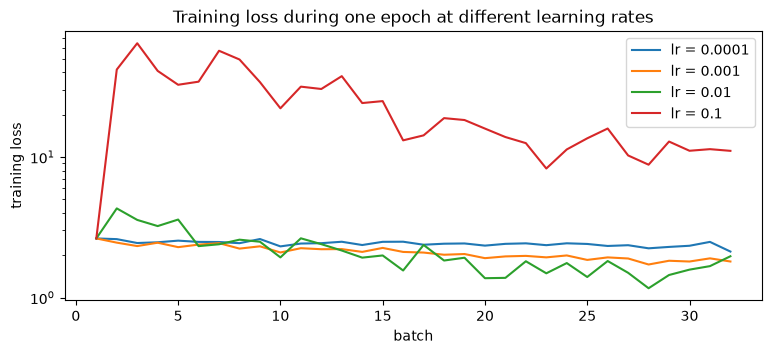

In [56]:
plt.figure(figsize=(9, 3.5))
for lr, losses in lr_curves.items():
    plt.plot(range(1, len(losses) + 1), losses, label=f"lr = {lr:g}")
plt.title("Training loss during one epoch at different learning rates")
plt.xlabel("batch"); plt.ylabel("training loss"); plt.yscale("log"); plt.legend()
plt.show()

### Learning-rate schedulers

*Slide: "Learning-rate schedulers".*

A good learning rate early in training is often too large later on, when the model needs small, careful steps to settle into a minimum. A **scheduler** changes the learning rate during training. `ReduceLROnPlateau` watches the validation loss and **multiplies the learning rate by `factor`** (here 0.1) when the loss stops improving for `patience` epochs.

You call `scheduler.step(val_loss)` **once per epoch, after validation**, passing the value it should watch. We start a fresh head-only model at a deliberately high learning rate, `1e-2`, so there is something for the scheduler to fix.

In [57]:
set_seed(SEED)
es_model = build_model()
optimizer = torch.optim.Adam(es_model.fc.parameters(), lr=1e-2)     # deliberately high start
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=0)
print("scheduler:", type(scheduler).__name__, "| starting lr:", optimizer.param_groups[0]["lr"])
MAX_EPOCHS, PATIENCE = (8, 2) if QUICK_RUN else (30, 3)     # used by the early-stopping loop below

scheduler: ReduceLROnPlateau | starting lr: 0.01


### Early stopping with a best checkpoint

*Slide: "Early stopping".*

If we train for too long, the model starts to **overfit**: training loss keeps falling, validation loss starts rising. **Early stopping** watches the validation loss: whenever it reaches a new best we save a **checkpoint** (`best_model.pt`); if it fails to improve for `PATIENCE` epochs in a row we stop. At the end we reload the best checkpoint, not the last weights. The loop below combines the scheduler and early stopping and prints the learning rate used in each epoch. We train on the same 2,000-image subset to keep it quick.

In [58]:
best_val, bad_epochs, es_hist = float("inf"), 0, {"train_loss": [], "val_loss": []}
for epoch in range(1, MAX_EPOCHS + 1):
    lr_now = optimizer.param_groups[0]["lr"]
    tr_loss, _ = train_one_epoch(es_model, small_train_loader, optimizer, criterion)
    va_loss, va_acc = evaluate(es_model, val_loader, criterion)
    scheduler.step(va_loss)                                   # may lower the lr for the next epoch
    es_hist["train_loss"].append(tr_loss); es_hist["val_loss"].append(va_loss)
    print(f"epoch {epoch}: lr {lr_now:.0e} | train loss {tr_loss:.3f} | val loss {va_loss:.3f} ({va_acc:.1%})")
    if va_loss < best_val:                                    # new best -> save a checkpoint
        best_val, bad_epochs = va_loss, 0
        torch.save(es_model.state_dict(), "best_model.pt")
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping: no improvement for {PATIENCE} epochs"); break

train:   0%|          | 0/32 [00:00<?, ?it/s]

train:  53%|█████▎    | 17/32 [00:01<00:00, 16.44it/s]

epoch 1: lr 1e-02 | train loss 2.133 | val loss 1.123 (60.9%)


train:   0%|          | 0/32 [00:00<?, ?it/s]

train:  53%|█████▎    | 17/32 [00:01<00:00, 16.67it/s]

epoch 2: lr 1e-02 | train loss 1.363 | val loss 1.072 (63.9%)


... (17 outputs left out)

train:   0%|          | 0/32 [00:00<?, ?it/s]

train:  44%|████▍     | 14/32 [00:01<00:01, 13.11it/s]

train:  88%|████████▊ | 28/32 [00:02<00:00, 13.21it/s]

epoch 8: lr 1e-03 | train loss 0.982 | val loss 0.960 (66.3%)


Did early stopping trigger in your run? If the validation loss kept improving, all `MAX_EPOCHS` epochs ran and you won't see the "early stopping" message. That is fine: the loop only stops when it should. Also look at the learning-rate column: each time the validation loss failed to improve, the scheduler cut the learning rate by 10×.

Finally, reload the best checkpoint and confirm that its validation loss equals the best value recorded above.

In [59]:
es_model.load_state_dict(torch.load("best_model.pt", map_location=device))
reloaded_loss, reloaded_acc = evaluate(es_model, val_loader, criterion)
print(f"best val loss during training: {best_val:.3f} | reloaded checkpoint: {reloaded_loss:.3f} ({reloaded_acc:.1%})")

best val loss during training: 0.960 | reloaded checkpoint: 0.960 (66.3%)


### Reading learning curves

*Slide: "Reading learning curves".*

Learning curves are your main diagnostic tool. The chart below shows the training and validation loss from the early-stopping run. Common patterns and their fixes:

- **Underfitting**: both losses stay high and close together. The model is too simple or hasn't trained enough. *Fix:* train longer, unfreeze more layers, raise the learning rate, or use a bigger model.
- **Overfitting**: training loss keeps falling while validation loss flattens or rises, opening a gap. *Fix:* more data or augmentation, regularisation (weight decay, dropout), freeze more layers, early stopping.
- **Noisy, jumpy curves**: the learning rate is probably too high or the batches too small (or the validation set is tiny, as in quick mode). *Fix:* lower the learning rate, use a scheduler, a larger batch, or a larger validation set.

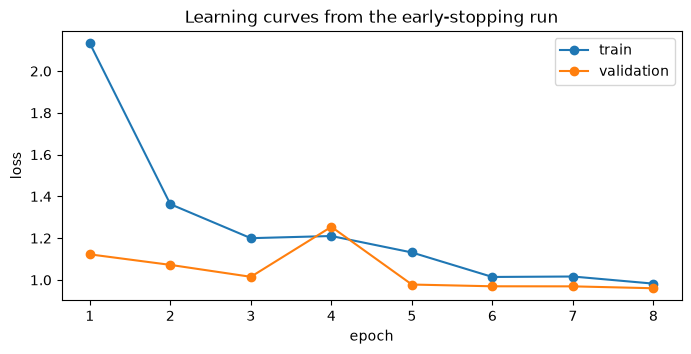

In [60]:
epochs_run = range(1, len(es_hist["train_loss"]) + 1)
plt.figure(figsize=(8, 3.5))
plt.plot(epochs_run, es_hist["train_loss"], "o-", label="train")
plt.plot(epochs_run, es_hist["val_loss"], "o-", label="validation")
plt.title("Learning curves from the early-stopping run")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.xticks(list(epochs_run)); plt.legend()
plt.show()

### Optional: automatic tuning with Optuna

*Slide: "Hyperparameter search".*

Trying settings by hand gets tedious. **Optuna** automates the search: you write an `objective` function that trains a model with suggested hyperparameters and returns a validation score, and Optuna chooses which values to try next. Here we tune the learning rate and the **weight decay** (a penalty that keeps weights small), both on a **log scale**.

**The test set is never used for tuning.** If you pick hyperparameters by test score, the test score is no longer an honest estimate of performance on new data. This cell is off by default; set `RUN_OPTUNA = True` in the configuration cell (it takes a few minutes).

In [61]:
if RUN_OPTUNA:
    import optuna
    def objective(trial):
        lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)              # log scale
        wd = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
        set_seed(SEED); m = build_model()
        opt = torch.optim.Adam(m.fc.parameters(), lr=lr, weight_decay=wd)
        train_one_epoch(m, small_train_loader, opt, criterion)
        return evaluate(m, val_loader, criterion)[1]                      # VALIDATION accuracy, never test
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=4)
    print("best:", study.best_params, f"| val accuracy: {study.best_value:.1%}")
else:
    print("Skipped. Set RUN_OPTUNA = True in the configuration cell to run this search.")

Skipped. Set RUN_OPTUNA = True in the configuration cell to run this search.


### Best-practice checklist

*Slide: "Best-practice checklist".*

| Data | Training | Evaluation |
|---|---|---|
| • Look at your images and labels<br>• Check the class balance<br>• Split train / val / test **before** anything else<br>• Augment the training set only, with label-preserving transforms<br>• Normalise to match the pretrained weights | • Start from pretrained weights<br>• Overfit one batch first<br>• Pick the learning rate on a log scale<br>• Use a scheduler and early stopping<br>• Set seeds and save the best checkpoint | • Tune on validation, test **once**<br>• Report per-class metrics, not just accuracy<br>• Read the confusion matrix<br>• Look at the mistakes<br>• Choose metrics that match the real cost of errors |

### Key takeaways

- Parameters are learned; hyperparameters are chosen by you, using the validation set.
- Always overfit one batch first: if the model can't memorise 32 images, there is a bug.
- Search learning rates on a log scale; use a scheduler to lower it and early stopping to keep the best checkpoint.
- Learning curves tell you whether you are underfitting, overfitting, or using too high a learning rate.

### Try it yourself

1. Break the sanity check on purpose: comment out `opt.step()` and re-run it. What does the loss do?
2. Change `patience=0` to `patience=1` in the scheduler. How does the learning-rate column change?
3. Set `RUN_OPTUNA = True` and run the search. Is the best learning rate close to the one that looked best in the comparison plot?

<details><summary>Solution</summary>

1. The loss stays exactly the same at every step, because the weights are never updated. This is exactly the kind of bug the sanity check catches.
2. The learning rate is only reduced after two epochs in a row without improvement, so it stays high for longer.
3. Usually it is in the same region. With only 4 trials and 1 epoch each, the search is very rough; real searches use more trials.

</details>

## 8. Beyond classification

*Lecture section 08: Beyond classification.*

Classification answers *"what is in this image?"*. **Object detection** also answers *"where?"*, by drawing a **bounding box** around each object. TorchVision describes a box with four numbers in **`[x1, y1, x2, y2]`** format: the top-left corner `(x1, y1)` and the bottom-right corner `(x2, y2)`, in pixels, with `y` counting **down** from the top.

`draw_bounding_boxes` draws boxes onto a `uint8` image tensor of shape `[3, H, W]`. We upscale a CIFAR image to 256 × 256 and draw one example box by hand.

image tensor: (3, 256, 256) torch.uint8


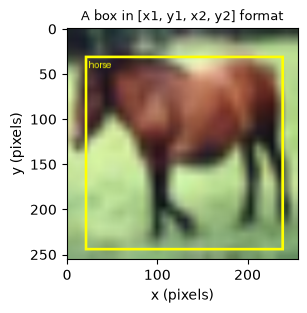

In [62]:
sample_img, sample_label = raw_train[SAMPLE_IDX]
big = T.Resize(256)(sample_img)                     # upscale so the box is easy to see
big_t = T.PILToTensor()(big)                        # uint8 tensor [3, H, W], as draw_bounding_boxes needs
print("image tensor:", tuple(big_t.shape), big_t.dtype)
boxes = torch.tensor([[20, 30, 240, 245]])          # one box: [x1, y1, x2, y2] in pixels
boxed = draw_bounding_boxes(big_t, boxes, labels=[classes[sample_label]], colors="yellow", width=3)

plt.figure(figsize=(3, 3))
plt.imshow(boxed.permute(1, 2, 0))
plt.title("A box in [x1, y1, x2, y2] format", fontsize=9)
plt.xlabel("x (pixels)"); plt.ylabel("y (pixels)")
plt.show()

### Optional: a pretrained object detector

TorchVision also includes pretrained **detectors**. Faster R-CNN takes a **list** of images and returns, for each one, a dictionary of `boxes`, `labels` (COCO classes) and confidence `scores`. We keep only detections with a score above 0.5.

This cell is off by default because the detector weights are a large download (about 170 MB). Set `RUN_DETECTOR = True` in the configuration cell to try it. On a tiny upscaled CIFAR image, don't expect perfect results. **How** detectors work (sliding windows → R-CNN → YOLO) is the topic of the next lecture.

In [63]:
if RUN_DETECTOR:
    from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
    det_weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    detector = fasterrcnn_resnet50_fpn_v2(weights=det_weights).eval().to(device)
    x = det_weights.transforms()(big_t).to(device)        # uint8 -> float in [0, 1]
    with torch.no_grad():
        out = detector([x])[0]                            # list of images in, list of dicts out
    keep = out["scores"] > 0.5
    print("boxes [x1, y1, x2, y2]:", out["boxes"][keep].round().tolist())
    print("labels:", [det_weights.meta["categories"][i] for i in out["labels"][keep].tolist()])
    print("scores:", [round(v, 2) for v in out["scores"][keep].tolist()])
else:
    print("Skipped. Set RUN_DETECTOR = True in the configuration cell to run the detector.")

Skipped. Set RUN_DETECTOR = True in the configuration cell to run the detector.


### Key takeaways

- Detection predicts *where* objects are as well as *what* they are.
- TorchVision boxes use `[x1, y1, x2, y2]` pixel coordinates, top-left to bottom-right.
- `draw_bounding_boxes` needs a `uint8` `[3, H, W]` tensor; `T.PILToTensor()` gives one.
- Pretrained detectors load with `weights=` just like classifiers, but take a list of images and return a list of dictionaries.

### Try it yourself

1. Draw a second box with a different colour around just the head of the object. (Hint: pass a `[2, 4]` tensor of boxes and two labels.)
2. What is the width and height of the box `[20, 30, 240, 245]`?

<details><summary>Solution</summary>

1. ```python
   boxes = torch.tensor([[20, 30, 240, 245], [150, 40, 240, 130]])
   boxed = draw_bounding_boxes(big_t, boxes, labels=["object", "head"], colors=["yellow", "red"], width=3)
   ```
   Adjust the second box's numbers to fit your image.
2. Width = x2 − x1 = 220 pixels, height = y2 − y1 = 215 pixels.

</details>

## 9. Summary

### The whole pipeline

1. **Image**: a grid of numbers, `[H, W, C]` in PIL/NumPy, `[C, H, W]` in PyTorch.
2. **Transforms**: `ToTensor` → `Resize` / `CenterCrop` → `Normalize`, combined with `T.Compose`; augmentation for training only.
3. **Dataset**: `datasets.CIFAR10(..., transform=...)`, with a proper train / validation / test split using `Subset`.
4. **DataLoader**: shuffled batches `[N, C, H, W]` for training, fixed order for evaluation.
5. **Pretrained model**: `resnet18(weights=ResNet18_Weights.DEFAULT)` with a new `fc` head.
6. **Train / evaluate**: the five-step loop; feature extraction, then fine-tuning; confusion matrix and per-class metrics.
7. **Save**: `torch.save(model.state_dict(), ...)` and `load_state_dict` into a freshly built model.

### Three key takeaways

- **TorchVision gives you the building blocks** (datasets, transforms, pretrained models), so a strong image classifier needs only a few dozen lines.
- **Preprocessing must match the model**: the right size, the right normalisation, and augmentation only where it keeps the label true.
- **Transfer learning and honest evaluation go together**: reuse a pretrained backbone, tune on validation, test once, and look beyond accuracy.

### Extension exercises

1. **Try ResNet-50**: swap in `resnet50(weights=ResNet50_Weights.DEFAULT)`. The new head becomes `nn.Linear(2048, 10)`. Is it more accurate? How much slower is it?
2. **Add `RandomErasing`**: put `T.RandomErasing(p=0.25)` at the end of `train_tf` (it works on tensors, so it goes after `ToTensor`). Does it reduce overfitting?
3. **Train at a larger `IMG_SIZE`**: set `QUICK_RUN = False` (or just `IMG_SIZE = 224`) on a GPU and compare accuracy and training time.
4. **Compare normalisations**: use the CIFAR-computed `cifar_mean` / `cifar_std` instead of the ImageNet values in both pipelines. Does it change the accuracy of the pretrained model?